# Generative Adversarial Networks (GANs)

**Generative Adversarial Networks (GANs)** are a type of deep learning model introduced by **Ian Goodfellow and his colleagues in 2014**. They consist of two neural networks that compete with each other to learn patterns from training data and generate new, realistic data, such as images, audio, and videos.

# StyleGAN

**StyleGAN** is an advanced generative adversarial network architecture developed by **NVIDIA researchers (Karras et al.) in 2018**. It is widely known for generating highly realistic images, particularly human faces, as demonstrated by websites such as *thispersondoesnotexist.com*.

Unlike traditional GANs, which directly feed random noise into the generator, StyleGAN uses a **style-based generator architecture** that provides greater control over different image features, from coarse structures to fine details.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import torchvision.utils as vutils
import matplotlib.pyplot as plt
import numpy as np


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 128
z_dim = 32
w_dim = 32
epochs = 10

print(f"[+] Execution Target Device: {device}")

[+] Execution Target Device: cpu


In [ ]:
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [ ]:
full_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
subset_indices = torch.randperm(len(full_dataset))[:5000]
dataset = Subset(full_dataset, subset_indices)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)

In [ ]:
class MappingNetwork(nn.Module):
    """Transforms standard Gaussian noise into an untangled intermediate style space W."""
    def __init__(self, z_dim=32, w_dim=32):
        super().__init__()
        self.mapping = nn.Sequential(
            nn.Linear(z_dim, w_dim),
            nn.ReLU(),
            nn.Linear(w_dim, w_dim),
            nn.ReLU()
        )
    def forward(self, z):
        return self.mapping(z)

class AdaIN(nn.Module):
    """Adaptive Instance Normalization modulates standard feature layers using explicit style bounds."""
    def __init__(self, channels, w_dim=32):
        super().__init__()
        self.instance_norm = nn.InstanceNorm2d(channels, affine=False)
        self.style_scale = nn.Linear(w_dim, channels)
        self.style_bias = nn.Linear(w_dim, channels)

    def forward(self, x, w):
        x_norm = self.instance_norm(x)
        gamma = self.style_scale(w).unsqueeze(-1).unsqueeze(-1)
        beta = self.style_bias(w).unsqueeze(-1).unsqueeze(-1)
        return gamma * x_norm + beta

In [ ]:
class SynthesisBlock(nn.Module):
    """Structural synthesis layer that upsamples maps and maps injected styles."""
    def __init__(self, in_channels, out_channels, w_dim=32):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=2, mode='nearest') # Nearest mode saves compute over Bilinear
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.adain = AdaIN(out_channels, w_dim)
        self.relu = nn.ReLU()

    def forward(self, x, w):
        return self.relu(self.adain(self.conv(self.upsample(x)), w))

class StyleGenerator(nn.Module):
    """StyleGAN Generator incorporating a learned starter matrix and structural layers."""
    def __init__(self, z_dim=32, w_dim=32):
        super().__init__()
        self.mapping = MappingNetwork(z_dim, w_dim)
        self.learned_constant = nn.Parameter(torch.randn(1, 32, 4, 4))

        self.block1 = SynthesisBlock(32, 32, w_dim)
        self.block2 = SynthesisBlock(32, 16, w_dim)
        self.block3 = SynthesisBlock(16, 8, w_dim)
        self.to_grayscale = nn.Conv2d(8, 1, kernel_size=1)

    def forward(self, z, return_w=False, custom_w=None):
        w = self.mapping(z) if custom_w is None else custom_w
        x = self.learned_constant.repeat(z.size(0), 1, 1, 1)

        x = self.block1(x, w)
        x = self.block2(x, w)
        x = self.block3(x, w)

        out = torch.tanh(self.to_grayscale(x))
        return (out, w) if return_w else out

class Discriminator(nn.Module):
    """Standard Downsampling Convolutional Discriminator."""
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),  # 32x32 -> 16x16
            nn.LeakyReLU(0.2),
            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1), # 16x16 -> 8x8
            nn.LeakyReLU(0.2),
            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.model(x)


In [ ]:
netG = StyleGenerator(z_dim, w_dim).to(device)
netD = Discriminator().to(device)

optG = optim.Adam(netG.parameters(), lr=0.0004, betas=(0.5, 0.999))
optD = optim.Adam(netD.parameters(), lr=0.0004, betas=(0.5, 0.999))
criterion = nn.BCELoss()

print("\n[+] Initializing Accelerated Training Loop...")
for epoch in range(epochs):
    lossD_accum = 0.0
    lossG_accum = 0.0

    for real_imgs, _ in dataloader:
        real_imgs = real_imgs.to(device)
        b_size = real_imgs.size(0)


        optD.zero_grad()

        labels_real = torch.ones(b_size, 1).to(device)
        output_real = netD(real_imgs)
        lossD_real = criterion(output_real, labels_real)

        z = torch.randn(b_size, z_dim).to(device)
        fake_imgs = netG(z)
        labels_fake = torch.zeros(b_size, 1).to(device)
        output_fake = netD(fake_imgs.detach())
        lossD_fake = criterion(output_fake, labels_fake)

        lossD = lossD_real + lossD_fake
        lossD.backward()
        optD.step()
        lossD_accum += lossD.item()

        optG.zero_grad()

        output_g = netD(fake_imgs)
        lossG = criterion(output_g, labels_real)
        lossG.backward()
        optG.step()
        lossG_accum += lossG.item()

    print(f"Epoch [{epoch+1:02d}/{epochs:02d}] | Loss D: {lossD_accum/len(dataloader):.4f} | Loss G: {lossG_accum/len(dataloader):.4f}")

print("[+] Training complete! Generating visual outputs...")


[+] Initializing Accelerated Training Loop...
Epoch [01/10] | Loss D: 0.8400 | Loss G: 0.9417
Epoch [02/10] | Loss D: 0.9216 | Loss G: 1.2951
Epoch [03/10] | Loss D: 1.4191 | Loss G: 0.8979
Epoch [04/10] | Loss D: 1.4982 | Loss G: 0.8522
Epoch [05/10] | Loss D: 1.4305 | Loss G: 0.8370
Epoch [06/10] | Loss D: 1.4408 | Loss G: 0.8454
Epoch [07/10] | Loss D: 1.3843 | Loss G: 0.8235
Epoch [08/10] | Loss D: 1.4995 | Loss G: 0.7917
Epoch [09/10] | Loss D: 1.3464 | Loss G: 0.8003
Epoch [10/10] | Loss D: 1.4065 | Loss G: 0.7709
[+] Training complete! Generating visual outputs...


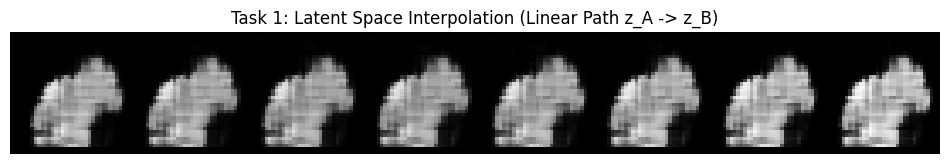

In [ ]:
netG.eval()
with torch.no_grad():
    z_A = torch.randn(1, z_dim).to(device)
    z_B = torch.randn(1, z_dim).to(device)

    interpolation_steps = 8
    steps = torch.linspace(0, 1, interpolation_steps).to(device)
    interpolated_imgs = []

    for alpha in steps:
        z_interp = (1 - alpha) * z_A + alpha * z_B
        img = netG(z_interp)
        interpolated_imgs.append(img.squeeze(0).cpu())

    grid_interp = vutils.make_grid(interpolated_imgs, nrow=interpolation_steps, normalize=True)

    plt.figure(figsize=(12, 4))
    plt.imshow(np.transpose(grid_interp.numpy(), (1, 2, 0)), cmap='gray')
    plt.axis('off')
    plt.title("Task 1: Latent Space Interpolation (Linear Path z_A -> z_B)")
    plt.show()


In [ ]:
z1 = torch.randn(1, z_dim).to(device)
z2 = torch.randn(1, z_dim).to(device)

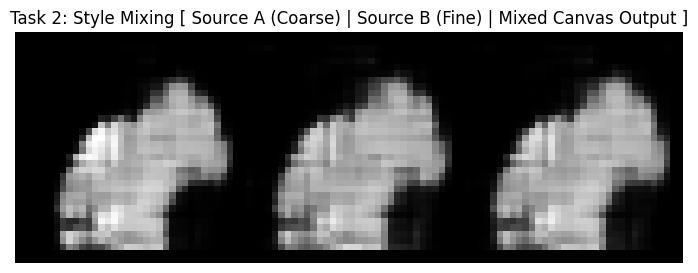

In [ ]:
    img1, w1 = netG(z1, return_w=True)
    img2, w2 = netG(z2, return_w=True)

    x_mix = netG.learned_constant.repeat(1, 1, 1, 1)
    x_mix = netG.block1(x_mix, w1)
    x_mix = netG.block2(x_mix, w1)
    x_mix = netG.block3(x_mix, w2)
    mixed_img = torch.tanh(netG.to_grayscale(x_mix))

    combined = torch.cat([img1, img2, mixed_img], dim=0).cpu()
    grid_mix = vutils.make_grid(combined, nrow=3, normalize=True)

    plt.figure(figsize=(9, 3))
    plt.imshow(np.transpose(grid_mix.numpy(), (1, 2, 0)), cmap='gray')
    plt.axis('off')
    plt.title("Task 2: Style Mixing [ Source A (Coarse) | Source B (Fine) | Mixed Canvas Output ]")
    plt.show()